## Лабораторный практикум по курсу «Разговорный ИИ и большие языковые модели», Университет ИТМО, 2026  
**Лабораторная работа №4**

### Задание

1. Развернуть векторную базу (например https://qdrant.tech/)
2. Выбрать датасет (например https://huggingface.co/datasets/mteb/fiqa) и инициализировать
коллекцию
3. Векторизовать семантической (например вашей обученной) и лексической (например
https://qdrant.tech/documentation/edge/edge-bm25/) моделями документы и загрузить их в
коллекцию
4. Настроить приемлемые скорость и качество поиска, подобрав их под вашу конфигурацию
машины (для старта можно взять начальные параметры)
5. Замерить качество гибридного поиска с шагом альфа 0.1 (нет необходимости производить
множество запросов с разными альфа, можно реализовать фьюжн и ручной расчет вне вбд)

### 0. Импорты

In [ ]:
import torch
import pickle
import numpy as np
from tqdm import tqdm
from rank_bm25 import BM25Okapi
import matplotlib.pyplot as plt
from datasets import load_dataset
from qdrant_client import QdrantClient
from fastembed import SparseTextEmbedding
from qdrant_client.models import PointStruct
from qdrant_client.models import SparseVector
from sentence_transformers import SentenceTransformer
from qdrant_client.models import Distance, VectorParams, SparseVectorParams


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


### 1. Разворачивание векторой базы

В качестве векторной базы данных была выбрана **Qdrant**.

Причины:

- Гибридный поиск «из коробки»: Qdrant позволяет хранить в одной коллекции оба типа векторов: dense (семантика) и sparse (лексика, BM25);
- Хранение payload: тексты документов хранятся в базе и возвращаются сразу с результатами поиска, без обращения к внешним источникам;
- Простое развертывание.

In [4]:
client = QdrantClient(path="./qdrant_fiqa")

/tmp/ipykernel_23059/1044108790.py:1: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <fiqa_hybrid> contains 57638 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  client = QdrantClient(path="./qdrant_fiqa")


### 2. Выбор датасета и подготовка данных

**Датасет:** `mteb/fiqa` (Financial Opinion Mining and Question Answering) - англоязычный датасет для оценки информационного поиска.

- Подходит для задачи «запрос - документ».

- Представляет собой классический формат BEIR: содержит корпус документов (`corpus`), запросы (`queries`) и разметку релевантности (`qrels`).

- Содержит финансовые вопросы и ответы (требует точного совпадения терминов и понимания контекста).

### Разбиение и структура

| Компонент | Количество | Формат / Примечание |
| :--- | :--- | :--- |
| `corpus` | 57 638 | `_id`, `title`, `text` (текст документа) |
| `queries` | 6 648 | `_id`, `text` (текст запроса) |
| `qrels` (test) | 1 706 | `query-id`, `corpus-id`, `score` |

Для лабораторной работы будет использоваться тестовая часть разметки (`qrels`), чтобы оценить качество гибридного поиска на реальных парах «запрос-документ».

In [7]:
# Корпус документов
corpus = load_dataset("mteb/fiqa", "corpus", split="corpus")

# Запросы
queries = load_dataset("mteb/fiqa", "queries", split="queries")

# Разметка (qrels) из дефолтной конфигурации
qrels = load_dataset("mteb/fiqa", split="test")

print(f"Документов: {len(corpus)}")
print(f"Запросов: {len(queries)}")
print(f"Строк в разметке (qrels): {len(qrels)}")
print("\nПример документа:", corpus[0])
print("Пример запроса:", queries[0])
print("Пример разметки:", qrels[0])

Документов: 57638
Запросов: 6648
Строк в разметке (qrels): 1706

Пример документа: {'_id': '3', 'title': '', 'text': "I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not their job - they're building software. Perhaps educational systems in the U.S. (or their students) should worry a little about getting marketable skills in exchange for their massive investment in education, rather than getting out with thousands in student debt and then complaining that they aren't qualified to do anything."}
Пример запроса: {'_id': '0', 'text': 'What is considered a business expense on a business trip?'}
Пример разметки: {'query-id': '8', 'corpus-id': '566392', 'score': 1.0}


In [9]:
documents_to_upload = []

for row in tqdm(corpus, desc="Подготовка текстов"):
    full_text = f"{row['title']} {row['text']}".strip()
    
    documents_to_upload.append({
        "id": int(row["_id"]),
        "text": full_text,
        "text_for_embedding": f"passage: {full_text}"
    })

print(f"Подготовлено документов: {len(documents_to_upload)}")

Подготовка текстов: 100%|██████████| 57638/57638 [00:02<00:00, 22122.93it/s]

Подготовлено документов: 57638


### 3. Векторизация семантической и лексической моделями документов и загрузка их в коллекцию

#### Семантическая (Dense)

`../lab_3/qa/results_new` - дообученная `intfloat/multilingual-e5-small` из Лабораторной работы №3.

- Архитектура на базе BERT (encoder-only), используется как bi-encoder.
- Модель была обучена ранее на датасете SberQuAD, в данной работе используется в готовом виде.
- Для корректной работы E5 добавлены префиксы query: (для запросов) и passage: (для документов).

#### Лексическая (Sparse)

`Qdrant/bm25` - встроенная в Qdrant реализация BM25.

- Классический вероятностный алгоритм (BM25), не требующий обучения.
- Учитывает частоту терминов (TF) и их редкость в корпусе (IDF).
- Работает на уровне отдельных токенов, обеспечивает точное совпадение терминов.

#### Характеристики

| Параметр | Dense (E5-small) | Sparse (BM25) |
| :--- | :--- | :--- |
| **Тип** | Нейросетевой энкодер | Статистический алгоритм |
| **Размерность** | 384 | Разреженный (до 30k) |
| **Обучение** | Дообучена на SberQuAD | Без обучения |
| **Сильные стороны** | Синонимы, контекст | Точные термины, аббревиатуры |
| **Слабые стороны** | Может пропускать точные совпадения | Не понимает смысл слов |

In [ ]:
#  Dense-модель
dense_model_path = "../lab_3/qa/results_new"
dense_model = SentenceTransformer(dense_model_path, device="cuda")

# Sparse-модель (BM25)
sparse_model = SparseTextEmbedding(model_name="Qdrant/bm25")

# Коллекция в Qdrant
collection_name = "fiqa_hybrid"

if not client.collection_exists(collection_name):
    client.create_collection(
        collection_name=collection_name,
        vectors_config={"dense": VectorParams(size=384, distance=Distance.COSINE)},
        sparse_vectors_config={"sparse": SparseVectorParams()}
    )
    print(f"Коллекция '{collection_name}' успешно создана.")
else:
    print(f"Коллекция '{collection_name}' уже существует.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Коллекция 'fiqa_hybrid' успешно создана.


In [ ]:
batch_size = 256

for i in tqdm(range(0, len(documents_to_upload), batch_size), desc="Загрузка в Qdrant"):
    batch = documents_to_upload[i : i + batch_size]
    
    texts_to_embed = [doc["text_for_embedding"] for doc in batch]
    
    # Dense векторы
    dense_vectors = dense_model.encode(texts_to_embed, batch_size=32, show_progress_bar=False).tolist()
    
    # Sparse векторы (BM25)
    sparse_vectors_gen = sparse_model.embed(texts_to_embed)
    sparse_vectors = [
        {"indices": vec.indices.tolist(), "values": vec.values.tolist()} 
        for vec in sparse_vectors_gen
    ]
    
    points = []
    for j, doc in enumerate(batch):
        points.append(
            PointStruct(
                id=doc["id"],
                vector={
                    "dense": dense_vectors[j],
                    "sparse": sparse_vectors[j]
                },
                payload={
                    "text": doc["text"]
                }
            )
        )
        
    client.upsert(collection_name=collection_name, points=points)

print("Загрузка завершена.")

Загрузка в Qdrant:  35%|███▍      | 78/226 [38:21<1:13:24, 29.76s/it]/tmp/ipykernel_4142692/3209963845.py:38: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Current collection contains 20224 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  client.upsert(collection_name=collection_name, points=points)
Загрузка в Qdrant: 100%|██████████| 226/226 [1:54:58<00:00, 30.52s/it]

Загрузка завершена.


In [ ]:
collection_info = client.get_collection(collection_name=collection_name)
print(f"Всего документов в коллекции: {collection_info.points_count}")

Всего документов в коллекции: 57638


### 4. Настройка скорости и качества поиска под конфигурацию машины

Для оптимизации скорости не делается запрос к Qdrant на каждой итерации alpha. Вместо этого один раз извлекается топ-100 сырых результатов из dense и sparse веток, после чего применяется MinMax-нормировку и взвешенную сумму в чистом Python. Это позволяет перебрать 11 значений alpha за один проход.

In [ ]:
# Подготовка qrels
qrels_dict = {}
for row in qrels:
    qid = str(row["query-id"])
    cid = int(row["corpus-id"])
    if qid not in qrels_dict:
        qrels_dict[qid] = set()
    if row["score"] > 0:
        qrels_dict[qid].add(cid)

test_queries = [q for q in queries if str(q["_id"]) in qrels_dict]

print(f"Собираем сырые результаты из Qdrant для {len(test_queries)} запросов...")
raw_results = {}

from qdrant_client.models import SparseVector

for q in tqdm(test_queries, desc="Сбор результатов"):
    qid = str(q["_id"])
    
    query_dense = dense_model.encode(f"query: {q['text']}").tolist()
    query_sparse = list(sparse_model.embed([f"query: {q['text']}"]))[0]
    query_sparse_vector = SparseVector(
        indices=query_sparse.indices.tolist(),
        values=query_sparse.values.tolist()
    )
    
    dense_res = client.query_points(collection_name=collection_name, query=query_dense, using="dense", limit=100).points
    sparse_res = client.query_points(collection_name=collection_name, query=query_sparse_vector, using="sparse", limit=100).points
    
    raw_results[qid] = {
        "dense": [(h.id, h.score) for h in dense_res],
        "sparse": [(h.id, h.score) for h in sparse_res],
        "relevant": qrels_dict[qid]
    }

print("Сбор завершен.")

Собираем сырые результаты из Qdrant для 648 запросов...


Сбор результатов: 100%|██████████| 648/648 [20:33<00:00,  1.90s/it]

Сбор завершен.


### 5. Замер качества гибридного поиска с шагом альфа 0.1

In [ ]:
def normalize_scores(results):
    if not results: return {}
    scores = [s for _, s in results]
    min_s, max_s = min(scores), max(scores)
    if max_s == min_s: return {id: 0.5 for id, _ in results}
    return {id: (s - min_s) / (max_s - min_s) for id, s in results}

alphas = np.arange(0.0, 1.1, 0.1)
final_results = []

print("Метрики для всех альф")
for alpha in alphas:
    mrr_sum = 0
    recall_sum = 0
    
    for qid, data in raw_results.items():
        # Нормируем скоры
        dense_norm = normalize_scores(data["dense"])
        sparse_norm = normalize_scores(data["sparse"])
        
        # Смешиваем вручную (фьюжн вне БД)
        all_ids = set(dense_norm.keys()) | set(sparse_norm.keys())
        hybrid_scores = {}
        for doc_id in all_ids:
            d_score = dense_norm.get(doc_id, 0)
            s_score = sparse_norm.get(doc_id, 0)
            hybrid_scores[doc_id] = alpha * d_score + (1 - alpha) * s_score
            
        # Берем топ-10
        top_10 = sorted(hybrid_scores.items(), key=lambda x: x[1], reverse=True)[:10]
        retrieved_ids = [doc_id for doc_id, _ in top_10]
        
        relevant = data["relevant"]
        
        # MRR@10
        rr = 0
        for rank, doc_id in enumerate(retrieved_ids, start=1):
            if doc_id in relevant:
                rr = 1 / rank
                break
        mrr_sum += rr
        
        # Recall@10
        hits = len(set(retrieved_ids) & relevant)
        recall_sum += hits / len(relevant) if relevant else 0
        
    mrr = mrr_sum / len(raw_results)
    recall = recall_sum / len(raw_results)
    final_results.append((alpha, mrr, recall))
    print(f"Alpha={alpha:.1f}: MRR@10={mrr:.4f}, Recall@10={recall:.4f}")

with open("hybrid_results.pkl", "wb") as f:
    pickle.dump(final_results, f)
print("\nРезультаты сохранены в hybrid_results.pkl")

Метрики для всех альф
Alpha=0.0: MRR@10=0.2711, Recall@10=0.2601
Alpha=0.1: MRR@10=0.2855, Recall@10=0.2678
Alpha=0.2: MRR@10=0.2980, Recall@10=0.2755
Alpha=0.3: MRR@10=0.3185, Recall@10=0.3006
Alpha=0.4: MRR@10=0.3309, Recall@10=0.3160
Alpha=0.5: MRR@10=0.3418, Recall@10=0.3216
Alpha=0.6: MRR@10=0.3179, Recall@10=0.3024
Alpha=0.7: MRR@10=0.2856, Recall@10=0.2659
Alpha=0.8: MRR@10=0.2658, Recall@10=0.2484
Alpha=0.9: MRR@10=0.2484, Recall@10=0.2262
Alpha=1.0: MRR@10=0.2330, Recall@10=0.2099

Результаты сохранены в hybrid_results.pkl


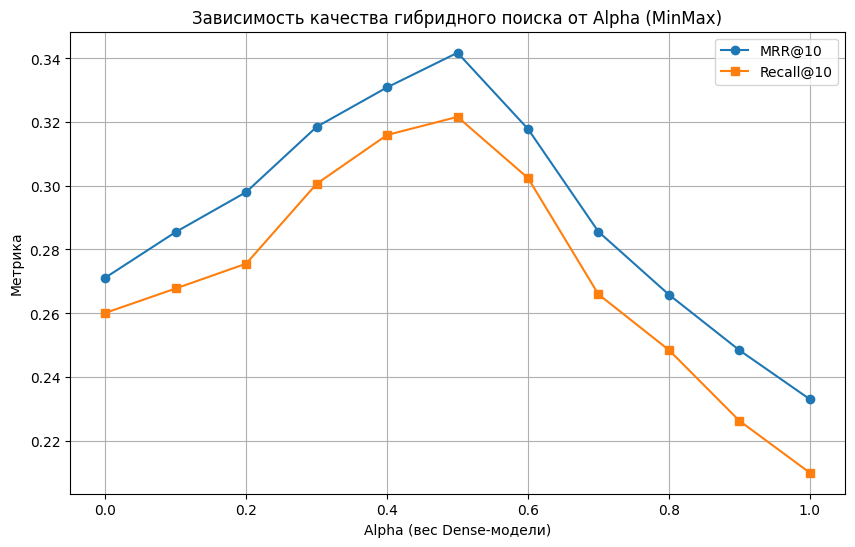

Лучшая Alpha: 0.5 (MRR@10 = 0.3418)


In [ ]:
alphas_list = [r[0] for r in final_results]
mrr_list = [r[1] for r in final_results]
recall_list = [r[2] for r in final_results]

plt.figure(figsize=(10, 6))
plt.plot(alphas_list, mrr_list, marker='o', label='MRR@10')
plt.plot(alphas_list, recall_list, marker='s', label='Recall@10')
plt.xlabel('Alpha (вес Dense-модели)')
plt.ylabel('Метрика')
plt.title('Зависимость качества гибридного поиска от Alpha (MinMax)')
plt.grid(True)
plt.legend()
plt.show()

best_idx = np.argmax(mrr_list)
print(f"Лучшая Alpha: {alphas_list[best_idx]:.1f} (MRR@10 = {mrr_list[best_idx]:.4f})")

### 6. Анализ результатов и выводы

В ходе эксперимента было оценено качество гибридного поиска при различных значениях коэффициента `alpha` (вес Dense-модели) от `0.0` до `1.0` с шагом `0.1`. В качестве метрик использовались **MRR@10** (Mean Reciprocal Rank) и **Recall@10**.

- `alpha = 0.0` - чистый лексический поиск (BM25). Показывает неплохой результат для точных терминов, но уступает гибриду.
- `alpha = 1.0` - чистый семантический поиск (дообученная E5). Показывает результат ниже пикового, так как модель может «размывать» точные совпадения специфических финансовых терминов.

#### Лучший результат

максимальное значение **MRR@10 = 0.3418** достигается при **`alpha = 0.5`**.

Это означает, что равный вклад семантической и лексической моделей (50% на 50%) обеспечивает наилучший баланс. Гибридный поиск превосходит как чистый BM25, так и чистую семантику: объединение сигналов разных типов (точное совпадение слов + контекстное понимание) даёт более качественную выдачу, чем любая из моделей по отдельности.

#### Реализация fusion

Cлияние реализовано **вручную вне векторной базы данных**. Результаты поиска по обоим типам векторов (dense и sparse) были извлечены из Qdrant один раз, а затем в чистом Python была применена MinMax-нормировка и взвешенная сумма:

$$
S_H = \alpha \cdot Z_D + (1 - \alpha) \cdot Z_S
$$

где \( Z_D \) и \( Z_S \) - нормированные скоры dense и sparse веток. Это позволило за один проход по данным оценить 11 вариантов `alpha` без повторных запросов к базе, что существенно ускорило эксперимент.